# p16_brief_factcheck: checking the brief's facts in code, and the 30 review briefs again

The labelled review pack (p11 section 5, labels from p15 and the tier-3 adjudication) found an unsupported claim in **5 of 30** briefs. They were not invented records: every id was real and the citation check passed. They were small factual embellishments next to correct citations:
- r06: a precedent described as "under the same project ID" when its project (P146314) is not the package's (P160005);
- r10: "recent similar contracts in the same project attracted between 2 and 6 bidding firms" when the project's two cited contracts had 2 and 5 (the 6-firm contract is in another project);
- r26: "smaller similar furniture contracts in the region" for Kenyan, Malawian and West African contracts cited for a Guyana package.

This notebook adds three changes to the agent and re-runs **the same 30 packages, replayed exactly as p11 does** (same notice texts, same "as of" date hiding, same held-out project, same cutoff benchmark table and cutoff forecast model):

1. **Records carry the facts explicitly** (`proc_rag_core`): each contract record has a `facts` line, and the number of firms is now counted exactly as the adjudication counted it (distinct firms in the award notices linked to the contract; "not recorded" when there is none).
2. **Writer rule 10**: counts, ranges, methods and project / country / region relations only from a cited record's fields; "same project" only when the ids match.
3. **A code fact-check** (`proc_intel.factcheck`, unit-tested on the adjudicated cases): a wrong count or range is replaced by the cited records' value (`factcheck_fixed`), any other unsupported statement is removed (`factcheck_removed`).

The writer also runs with **Qwen 3.5 thinking on (`reasoning_effort="high"`)**; the earlier pack was written with thinking off. The difference between the two packs is therefore the **combined effect** of the fact-check changes and thinking, not of either alone.

Outputs: `proc_gold.review_briefs_v2` and `data/human_review/review_briefs_v2.csv` (the same columns as `review_briefs.csv`, label columns empty) for the same three-tier labelling.

%md-sandbox
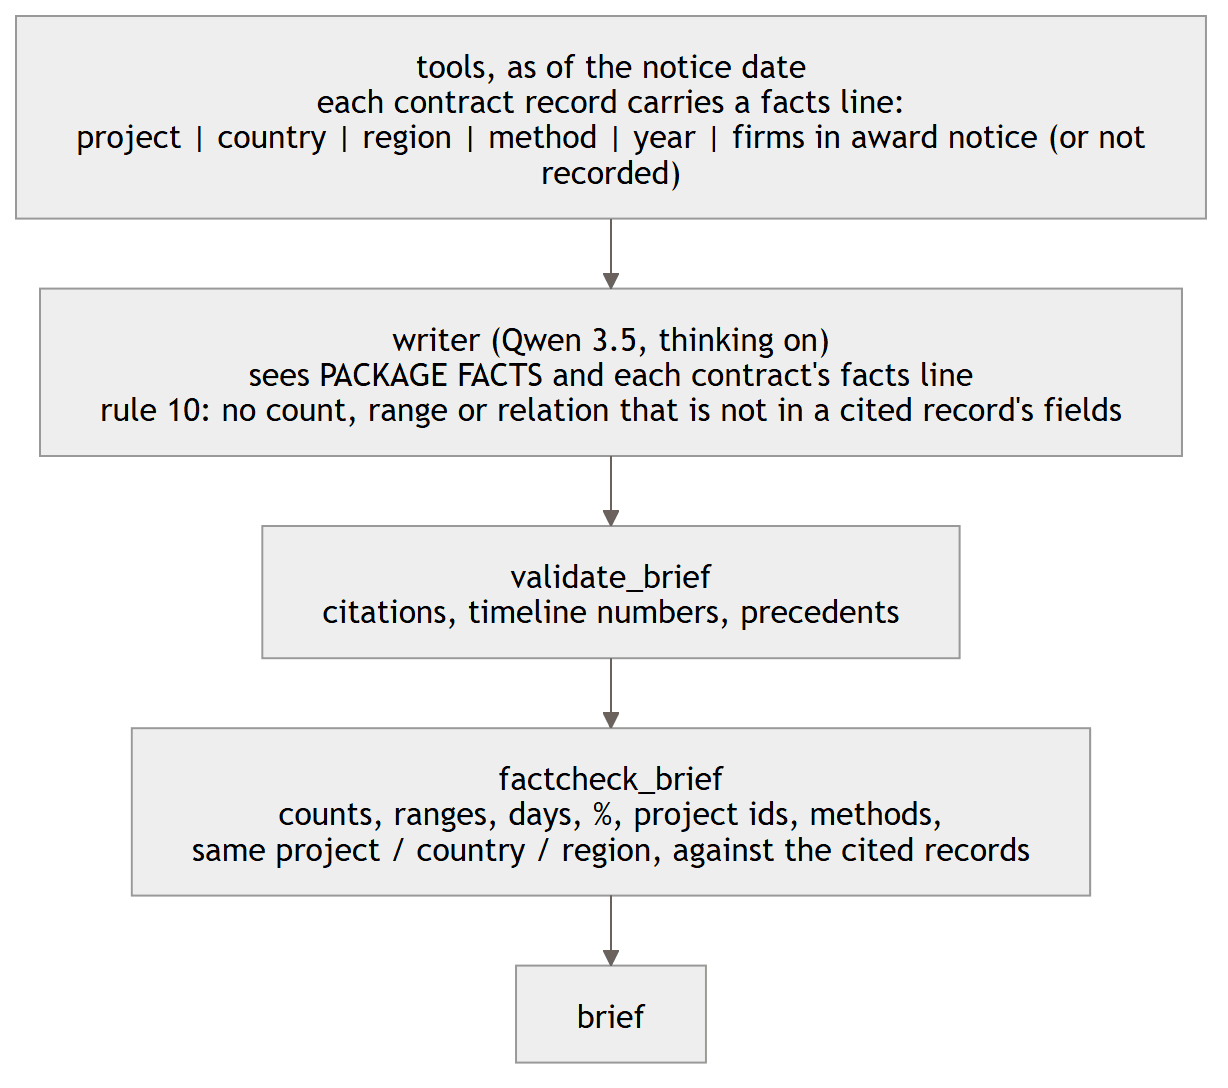


## Key design decisions

| Decision | Rationale | Evidence |
|---|---|---|
| Fix the errors with explicit record fields, a writer rule and a check in code, not with another judge | The errors are relations and numbers that the cited records contradict, so code can test them against the records | All five unsupported briefs cite real records; the errors are a relation ("same project", "in the region") or a firm range |
| The contract tool counts firms the adjudicator's way: distinct firms in the award-linked notices; an award notice that names no firm counts as "not recorded" | The count the writer quotes must be the count the labels are checked against | `tender_timelines.n_named_firms_in_award_notice` differs from that count on 6,188 of the 189,126 contracts with an award notice |
| A wrong count or range is replaced by the cited records' value; any other unsupported sentence is removed; advice and interpretive phrases are not checked | A number the records can correct keeps its sentence; a wrong relation cannot be repaired by code | Unit tests on the adjudicated cases (`tests/test_factcheck.py`): r06 removed, r10 fixed to "between 2 and 5", r26 removed; r05 "1 to 3 firms", r09 "up to 11", r18 "Request for Bids with 8 firms", r20 "1 to 8" kept |
| Writer thinking on (`WRITER_REASONING_EFFORT="high"`), planner thinking off; the completion budget grows by `THINKING_TOKENS` | Thinking lets the writer check each statement against the record fields; the planner only picks tool arguments, and its calls run one after another inside the replay | The endpoint accepts `reasoning_effort="high"` with a JSON schema and with tools: the reply carries a reasoning block and a text block (JSON) or tool calls |
| Tool half (`gather_evidence`) one package at a time inside `as_of`; writer half (`finish_brief`) three at a time | p11's `as_of` swaps caches that every tool shares, so two replays cannot run at once; the writer needs no tool | Final pass: tool half 425 s, writer half 1,094 s for 30 briefs |
| Round 2: a quantified claim ("all five", "each") must hold for every cited contract; region in the facts line; `tool_log` records make absences citable; the round-2 judge rubric treats advice as advice and checks gaps against `tool_log` | Reading the judge's 7 flags on the first v2 pack separated real errors from judge errors | One real overstatement (r30 "all five ... with 1 to 6 firms": one of the five has no award notice); "same region" was unverifiable without the region in the facts line; evidence-gap lines and mitigations were read as claims |
| Three writer threads; a throttled call waits up to a minute between retries; a brief that still fails is retried alone after the parallel pass; the tool half is saved to the volume | The Qwen endpoint's output-token limit per minute is shared with other users | The first full run with four thinking writers failed on HTTP 429; in the final pass 6 writer calls were throttled and all succeeded when retried alone |
| The final pass runs the writer and the judge on the Databricks endpoints; an OpenRouter pass of the same models was discarded | The provider switch was measured before it was trusted, and it was worse | OpenRouter pass: median latency 148 s per brief against 46 s, one holdout brief cut off at the token limit, more judge flags |
| The 30 contract ids are asserted against p11's review file, in order, before anything is written | A before/after comparison is only fair on the same packages | Assertion in section 1 |

Limitations: the packs differ in several things at once (record fields, prompt rules, thinking, fact-check, judge rubric), so the comparison shows their combined effect; interpretive phrases, amounts and mitigations are not checked by the code.

Full reasoning: docs/decision_log.md

## Setup

**What:** shared settings, the agent (`proc_rag_core`, now with the fact-check and the writer's thinking setting), and p11's replay code: the cohort features, the 300-package sample, the cutoff model A and benchmark table, `as_of`, the judges and the review selection, executed from p11's own source (read from the workspace) cell by cell. Only the definitions needed here are taken from the cells that also run evaluations (for example the judge functions, not p11's 2,400 relevance judgements).

**Why:** the replay must be p11's, not a copy that could drift from it; reading the source at run time means a change to p11 is picked up here.

In [ ]:
%run ./proc_common

In [ ]:
dbutils.widgets.text("provider", "databricks")     # "openrouter": writer and judge through OpenRouter (evaluation only)
dbutils.widgets.text("suffix", "")                 # output suffix, e.g. "_or" for a parallel run
dbutils.widgets.text("writer_threads", "3")
LLM_PROVIDER = dbutils.widgets.get("provider")      # read by proc_rag_core

In [ ]:
%run ./proc_rag_core

In [ ]:
import ast
import base64
import statistics

from databricks.sdk import WorkspaceClient
from databricks.sdk.service.workspace import ExportFormat

dbutils.widgets.text("limit", "30")
LIMIT = int(dbutils.widgets.get("limit"))                      # a smaller number for a smoke run
WRITER_THREADS = int(dbutils.widgets.get("writer_threads"))    # 3 on the shared Databricks endpoints
SUFFIX = dbutils.widgets.get("suffix")
_here = os.path.dirname(dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get())
_p11 = base64.b64decode(WorkspaceClient().workspace.export(f"{_here}/p11_backtest", format=ExportFormat.SOURCE).content).decode()
P11_CELLS = ["\n".join(line for line in c.split("\n") if not line.startswith("# MAGIC") and line != "# Databricks notebook source")
             for c in _p11.split("# COMMAND ----------")]


def _defined(node):
    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        return {node.name}
    if isinstance(node, (ast.Assign, ast.AnnAssign)):
        targets = node.targets if isinstance(node, ast.Assign) else [node.target]
        return {n.id for t in targets for n in ast.walk(t) if isinstance(n, ast.Name)}
    if isinstance(node, (ast.Try, ast.With, ast.If)):            # e.g. try: with open(...): JCACHE = json.load(fh)
        inner = node.body + getattr(node, "orelse", []) + [n for h in getattr(node, "handlers", []) for n in h.body]
        return set().union(*(_defined(n) for n in inner))
    return set()


def run_p11(marker, names=None):
    """Execute the p11 cell containing `marker` in this notebook's namespace; with `names`, only the top-level
    statements that define those names."""
    cells = [c for c in P11_CELLS if marker in c]
    assert len(cells) == 1, f"p11 cell '{marker}': {len(cells)} matches"
    tree = ast.parse(cells[0])
    if names is not None:
        tree.body = [n for n in tree.body if _defined(n) & set(names)]
        missing = set(names) - set().union(*(_defined(n) for n in tree.body))
        assert not missing, f"p11 cell '{marker}' does not define {missing}"
    exec(compile(tree, f"p11_backtest[{marker[:30]}]", "exec"), globals())


run_p11("_CORE_NAMES = ")                                     # p11 setup: imports, seed, dates, paths
print(f"LLM provider for writer and judge: {LLM_PROVIDER} | output suffix '{SUFFIX}' | "
      f"writer reasoning effort: {WRITER_REASONING_EFFORT} | planner reasoning effort: {PLANNER_REASONING_EFFORT} | "
      f"writer threads {WRITER_THREADS} | per-call timeout {CALL_TIMEOUT_S} s, one retry")

snapshot 2026-10-13 | cohort 2019-07-01..2024-10-13 | test from 2023-07-01 | strict as-of training notices up to 2021-07-01 | agent entry point: run_agent | rerank=True
LLM provider for writer and judge: databricks | output suffix '' | writer reasoning effort: high | planner reasoning effort: none | writer threads 3 | per-call timeout 240 s, one retry


In [ ]:
run_p11('tl = spark.table(f"{GOLD}.tender_timelines")')       # 1a cohort features
run_p11("def slow_thresholds(")                               # 1b slow label and package texts
run_p11('test["stratum"] = ')                                 # 1c the 300-package sample
run_p11("model_a = fit_recipe(train, CAL_START)")             # 2a model A at the cutoff (+ p07 reproduction check)
run_p11("def benchmark_table(", ["benchmark_table", "cutoff_bench"])
run_p11("def as_of(")                                         # 3a hiding the future
run_p11("def judge_json(", ["_JUDGE_LOCK", "JCACHE", "save_judge_cache", "judge_json", "REL_SCHEMA", "REL_SYSTEM",
                            "judge_relevance"])
run_p11("GROUND_SCHEMA = ", ["order", "first", "review", "GROUND_SCHEMA", "GROUND_SYSTEM", "HAS_FORECAST_TOOL"])
run_p11("def short_text(", ["short_text"])

cohort 20,745 | train (notices before 2023-07-01) 14,121 | test 6,624 | strict as-of training rows (notices up to 2021-07-01) 5,837
slow base rate: train 0.250 | test 0.224 | package text from the notice for 100.0% of test contracts
sample: 300 packages from 299 projects and 92 countries; strata 28


stratum                                                   | population | allocated | sampled
----------------------------------------------------------+------------+-----------+--------
Eastern and Southern Africa | GO                          | 973        | 29        | 29     
Western and Central Africa | CW                           | 734        | 23        | 23     
Eastern and Southern Africa | CW                          | 719        | 22        | 22     
Eastern and Southern Africa | CS                          | 587        | 19        | 19     
Western and Central Africa | GO                           | 546        | 18        | 18     
South Asia | CW                                           | 339        | 13        | 13     
Western and Central Africa | CS                           | 302        | 12        | 12     
Middle East, North Africa, Afghanistan, and Pakistan | GO | 283        | 12        | 12     
Europe and Central Asia | GO                              | 260       

{'text/plain': 'Downloading artifacts:   0%|          | 0/27 [00:00<?, ?it/s]', 'application/vnd.jupyter.widget-view+json': {'version_major': 2, 'version_minor': 0, 'model_id': 'a001d537a5214cafa6d843bb29608c40'}}

champion v2 (run 5e227173): {'num_leaves': 63, 'min_data_in_leaf': 30}, rounds 158, classifier rounds 45, conformal shifts 0.1356 / 0.1123
refits done in 14 s | A: 14,121 rows, shifts +0.151 / +0.097 | B: 5,837 rows, shifts +0.260 / +0.154


metric                | p07 logged | this refit | difference
----------------------+------------+------------+-----------
test MAE (days)       | 76.1934    | 75.4623    | -0.731    
test P10-P90 coverage | 0.8071     | 0.8074     | 0.0003    
test mean pinball     | 24.5858    | 24.4324    | -0.1534   
conformal lower shift | 0.1356     | 0.1511     | 0.0155    
conformal upper shift | 0.1123     | 0.0966     | -0.0157   

contract index: 282,890 contracts, 8,540,368 non-zero term weights, built in 43 s
lesson passages: 21,118 ({'appraisal': 16623, 'completion': 4495})
contracts without a signing date: 0 | lesson passages without a date: 1698 of 21,118 (always hidden)


## 1. The same 30 packages

**What:** p11's review selection (first package per region x category stratum in hash order, then one more per region), checked against the contract ids of p11's review file in the same order.

**Why:** a before/after comparison is only fair on the same packages; the check makes a silent change of the sample impossible.

In [ ]:
v1_path = f"{REVIEW_DIR}/review_briefs.csv"
v1 = pd.read_csv(v1_path if os.path.exists(v1_path) else os.path.join(DATA_DIR, "human_review", "review_briefs.csv"),
                 dtype={"contract_id": str})
assert review["row_id"].astype(str).tolist() == v1["contract_id"].tolist(), "p11's review selection changed"
review = review.head(LIMIT)
print(f"{len(review)} packages, identical to p11's review pack (first: {review['row_id'].iloc[0]}, "
      f"last: {review['row_id'].iloc[-1]}); held-out projects {review['project_id'].nunique()}")

30 packages, identical to p11's review pack (first: 1884459, last: 1816748); held-out projects 30


## 2. Re-generating the briefs

**What:** for each package, the tool half of the agent (`gather_evidence`: guard, planner, tools) inside `as_of(notice date, project)` with the cutoff benchmark table and model A, exactly as p11 calls the agent; then the writer half (`run_agent_on_evidence`: writer with thinking, citation validation, fact-check) for all packages, three at a time. The leak check is p11's (`check_no_leak` on the cited precedents and lessons). A brief's latency is the sum of its two halves, i.e. what one sequential run would take.

**Why:** the writer needs no tool, so it can run outside `as_of`, in parallel; the tool half cannot, because `as_of` swaps caches every tool shares.

In [ ]:
import pickle

STATES_FILE = f"{BT_ROOT}/p16_gathered_{LIMIT}.pkl"      # the tool half, kept so a writer failure does not redo it
t0 = time.time()
cached = None
if os.path.exists(STATES_FILE):
    with open(STATES_FILE, "rb") as fh:
        cached = pickle.load(fh)
if cached and cached["contract_ids"] == review["row_id"].astype(str).tolist() and cached["core"] == WRITER_SYSTEM:
    states, t_gather = cached["states"], cached["t_gather"]
    print(f"tool half loaded from {STATES_FILE} (gathered in {t_gather:.0f} s)")
else:
    states = []
    for pkg in review.itertuples():
        package = {"description": pkg.query, "country": pkg.country_code, "category": pkg.procurement_category_code,
                   "method": pkg.procurement_method_name, "_exclude_projects": [pkg.project_id]}
        if HAS_FORECAST_TOOL:
            package.update(project_id=pkg.project_id, planned_notice_date=str(pkg.notice_date.date()))
        with as_of(pkg.notice_date, pkg.project_id, bench=cutoff_bench,
                   forecast_model=CutoffModel() if HAS_FORECAST_TOOL else None):
            states.append(gather_evidence(package))
    t_gather = time.time() - t0
    with open(STATES_FILE.replace(".pkl", f"{SUFFIX}.pkl"), "wb") as fh:      # a parallel run writes its own file
        pickle.dump({"contract_ids": review["row_id"].astype(str).tolist(), "core": WRITER_SYSTEM, "states": states,
                     "t_gather": t_gather}, fh)


def write_one(state):
    """The writer half; a brief that still fails after the client's retries (the endpoint's output-token limit
    per minute is shared with other users) is retried once more after the parallel pass, on its own."""
    try:
        return run_agent_on_evidence(state)
    except RuntimeError as e:
        print(f"writer failed, retried later: {str(e)[:160]}")
        return None


t1 = time.time()
with ThreadPoolExecutor(max_workers=WRITER_THREADS) as pool:
    outs = list(pool.map(write_one, states))
retried = [i for i, o in enumerate(outs) if o is None]
for i in retried:
    time.sleep(30)
    outs[i] = run_agent_on_evidence(states[i])
t_write = time.time() - t1
print(f"writer retries after the parallel pass: {len(retried)}")
briefs = []
for pkg, out in zip(review.itertuples(), outs, strict=True):
    recs_ = out.get("cited_records") or {}
    retrieved = [r for r in recs_.values() if r["type"] != "contract" or r.get("close_precedent", True)]
    check_no_leak(retrieved, pkg.notice_date, pkg.project_id)
    out["_kg_future"] = leak_violations([r for r in recs_.values() if r["type"] == "contract" and not r.get("close_precedent", True)],
                                        str(pkg.notice_date.date()), [])
    briefs.append((pkg, out))
print(f"{len(briefs)} briefs: tool half {t_gather:.0f} s (one at a time), writer half {t_write:.0f} s "
      f"({WRITER_THREADS} at a time); statuses {pd.Series([o['status'] for o in outs]).value_counts().to_dict()}; "
      f"writer reasoning effort {sorted({str((o.get('writer') or {}).get('reasoning_effort')) for o in outs})}")

tool half loaded from /Volumes/dbw_wb_outcome/proc_bronze/raw/backtest/p16_gathered_30.pkl (gathered in 425 s)
writer failed, retried later: databricks-qwen35-122b-a10b failed: HTTP 429: {"error_code":"REQUEST_LIMIT_EXCEEDED","message":"REQUEST_LIMIT_EXCEEDED: Exceeded workspace output tokens per min
writer failed, retried later: databricks-qwen35-122b-a10b failed: HTTP 429: {"error_code":"REQUEST_LIMIT_EXCEEDED","message":"REQUEST_LIMIT_EXCEEDED: Exceeded workspace QPS rate limit for da
writer failed, retried later: databricks-qwen35-122b-a10b failed: HTTP 429: {"error_code":"REQUEST_LIMIT_EXCEEDED","message":"REQUEST_LIMIT_EXCEEDED: Exceeded workspace output tokens per min
writer failed, retried later: databricks-qwen35-122b-a10b failed: HTTP 429: {"error_code":"REQUEST_LIMIT_EXCEEDED","message":"REQUEST_LIMIT_EXCEEDED: Exceeded workspace output tokens per min
writer failed, retried later: databricks-qwen35-122b-a10b failed: HTTP 429: {"error_code":"REQUEST_LIMIT_EXCEEDED","message":

{'text/plain': '[Trace(trace_id=tr-077120d5f35766f3da6bae4353510bba), Trace(trace_id=tr-4060e878967312d665e4a080bac7f88b), Trace(trace_id=tr-9b57765f138305e0d8e9908e4c99f35b), Trace(trace_id=tr-b7dfcf040972c0533def7202d5534483), Trace(trace_id=tr-f29e863dff4513a2bfea5aeae29fae55), Trace(trace_id=tr-e59f7e14a7d25ab07a6d1e6016e0394c), Trace(trace_id=tr-60a120cc4417047045a34df74f09423c), Trace(trace_id=tr-c80cf99a3af589a8e73b4889fcde58a6), Trace(trace_id=tr-f2206afe978dd056ec0b2d53fe36d55a), Trace(trace_id=tr-175f3134d7f29c1909b91b388e2f3bff)]', 'application/databricks.mlflow.trace': '[{"trace_id": "tr-077120d5f35766f3da6bae4353510bba", "sql_warehouse_id": null}, {"trace_id": "tr-4060e878967312d665e4a080bac7f88b", "sql_warehouse_id": null}, {"trace_id": "tr-9b57765f138305e0d8e9908e4c99f35b", "sql_warehouse_id": null}, {"trace_id": "tr-b7dfcf040972c0533def7202d5534483", "sql_warehouse_id": null}, {"trace_id": "tr-f29e863dff4513a2bfea5aeae29fae55", "sql_warehouse_id": null}, {"trace_id": "t

## 3. The review file, scored as p11 scores it

**What:** one row per brief with exactly the columns of `review_briefs.csv` (the same automatic scores: timeline range vs the actual duration, the relevance judge on the precedents, the groundedness judge on the whole brief; label columns empty), written to the volume and published as `proc_gold.review_briefs_v2` with the fact-check columns added.

**Why:** the same columns let p15's three-tier labelling and the scoring scripts run on the new pack unchanged.

In [ ]:
# Round 2 rubric: p11's rubric, plus the three things its judge got wrong on the first v2 pack (it called
# mitigations and evidence gaps "unsupported claims" and could not see the package's own region).
GROUND_SYSTEM_V2 = GROUND_SYSTEM.replace("Return JSON", """Also NOT claims, never unsupported: mitigations and
recommendations (advice on what to do). Evidence-gap statements ARE checked, but against the TOOL_LOG records (what a
search did not find, which peer groups were skipped and why) and the PACKAGE FACTS line, not against contract records.
"Same project / same country / in the region" is supported when a cited record's project, country or region equals
the PACKAGE FACTS. "All" / "each" / "all five" claim a fact for every cited contract.
Return JSON""")
assert GROUND_SYSTEM_V2 != GROUND_SYSTEM, "p11's rubric text changed: update the round-2 additions"
pred_a_of = dict(zip(test["row_id"], pred_a.to_dict("records")))


def judge_json_role(system, user, schema, max_tokens=900):
    """p11's cached judge_json, with the call marked as a judge call (so the provider switch can route it)."""
    key = hashlib.sha1(json.dumps([JUDGE_MODEL, system, user]).encode()).hexdigest()
    with _JUDGE_LOCK:
        if key in JCACHE:
            return JCACHE[key], True
    v = None
    for _ in (1, 2):
        try:
            r = chat([{"role": "system", "content": system}, {"role": "user", "content": user}], JUDGE_MODEL,
                     max_tokens=max_tokens, response_format=schema, role="judge")
            v = json.loads(r["text"])
            break
        except Exception:
            v = None
    if v is not None:
        with _JUDGE_LOCK:
            JCACHE[key] = v
    return v, False


def judge_messages(pkg, out):
    """The groundedness judge's two messages for one brief: round-2 rubric input (with PACKAGE FACTS) and p11's."""
    package = {"description": pkg.query, "country": pkg.country_code, "category": pkg.procurement_category_code,
               "method": pkg.procurement_method_name, "project_id": pkg.project_id,
               "planned_notice_date": str(pkg.notice_date.date())}
    ev = "\n\n".join(_evidence_block(r)[:1600] for r in (out.get("cited_records") or {}).values())[:40000]
    facts = " | ".join(f"{k}: {v or 'not given'}" for k, v in package_facts(package).items())
    return (f"PACKAGE:\n{package_text(package)}\nPACKAGE FACTS: {facts}\n\nRECORDS:\n{ev}\n\nBRIEF:\n{out.get('text', '')}",
            f"PACKAGE:\n{package_text(package)}\n\nRECORDS:\n{ev}\n\nBRIEF:\n{out.get('text', '')}")


t2 = time.time()
jobs = [(system, msgs[k]) for pkg, out in briefs if out.get("brief")
        for msgs in [judge_messages(pkg, out)] for k, system in ((0, GROUND_SYSTEM_V2), (1, GROUND_SYSTEM))]
with ThreadPoolExecutor(max_workers=max(3, WRITER_THREADS)) as pool:          # fills the judge cache in parallel
    list(pool.map(lambda a: judge_json_role(a[0], a[1], GROUND_SCHEMA, max_tokens=1500), jobs))
print(f"{len(jobs)} groundedness judgements in {time.time() - t2:.0f} s")
rows_out, extra, full_cited = [], [], []
for i, (pkg, out) in enumerate(briefs, 1):
    package = {"description": pkg.query, "country": pkg.country_code, "category": pkg.procurement_category_code,
               "method": pkg.procurement_method_name, "project_id": pkg.project_id,
               "planned_notice_date": str(pkg.notice_date.date())}
    brief, recs, cited = out.get("brief") or {}, out.get("cited_records") or {}, out.get("cited_ids") or []
    u_new, u_old = judge_messages(pkg, out)
    tl_out = out.get("timeline") or {}
    model_tl, peer_tl = tl_out.get("model") or {}, tl_out.get("peer_group") or {}
    range_rec = model_tl if model_tl.get("p10_days") is not None else (peer_tl or None)
    auto_tl = None if not range_rec else bool(range_rec["p10_days"] <= pkg.days_notice_to_signing <= range_rec["p90_days"])
    prec_recs = [recs.get(p["record_id"]) or {"label": p.get("label")} for p in out.get("precedents", [])]
    auto_prec = sum(bool(judge_relevance(pkg.query, pkg.procurement_category_code, r)[0]) for r in prec_recs[:5])
    g, _ = judge_json_role(GROUND_SYSTEM_V2, u_new, GROUND_SCHEMA, max_tokens=1500) if brief else (None, False)
    g_old, _ = judge_json_role(GROUND_SYSTEM, u_old, GROUND_SCHEMA, max_tokens=1500) if brief else (None, False)  # p11's rubric
    full_cited.append(json.dumps([{"record_id": c, "text": (f"{recs[c]['facts']} | " if recs[c].get("facts") else "")
                                   + short_text(recs[c])[:400]} for c in cited if c in recs]))
    pa = pred_a_of[pkg.row_id]
    actual = (f"signed {str(pkg.signing_date)[:10]}, {int(pkg.days_notice_to_signing)} days from notice to signing "
              f"(slow for its peer group: {'yes' if pkg.slow else 'no'}); model A range P10-P90 "
              f"{pa['p10']:.0f}-{pa['p90']:.0f} days, P50 {pa['p50']:.0f}")
    rid = f"r{i:02d}"
    rows_out.append({"review_id": rid, "contract_id": pkg.row_id, "notice_id": pkg.notice_id, "project_id": pkg.project_id,
                     "country": pkg.country_code, "region": pkg.region, "category": pkg.procurement_category_code,
                     "method": pkg.procurement_method_name, "notice_date": str(pkg.notice_date.date()), "description": pkg.query,
                     "status": out.get("status"), "brief_text": out.get("text", ""),
                     "cited_records": json.dumps([{"record_id": c, "text": short_text(recs[c])[:400]} for c in cited if c in recs]),
                     "actual_days": int(pkg.days_notice_to_signing), "actual_outcome": actual,
                     "model_p50_days": model_tl.get("p50_days"), "peer_p50_days": peer_tl.get("p50_days"),
                     "auto_timeline_ok": auto_tl, "auto_precedents_relevant": auto_prec,
                     "auto_unsupported_claim": None if g is None else bool(g["any_unsupported"]),
                     "auto_unsupported_examples": "" if g is None else "; ".join(g["unsupported_claims"])[:400],
                     "model_range_days": (f"{model_tl['p10_days']:.0f}-{model_tl['p90_days']:.0f}" if model_tl.get("p10_days") is not None else ""),
                     "peer_range_days": (f"{peer_tl['p10_days']:.0f}-{peer_tl['p90_days']:.0f}" if peer_tl else ""),
                     "n_precedents": out.get("n_precedents"), "kg_records_after_notice": len(out.get("_kg_future") or []),
                     "n_tool_calls": len(out.get("tool_calls") or []), "latency_s": out.get("latency_s"),
                     "timeline_ok": "", "precedents_relevant": "", "risks_relevant": "", "any_unsupported_claim": "", "notes": ""})
    fc = out.get("factcheck") or {}
    w = out.get("writer") or {}
    extra.append({"review_id": rid, "factcheck_removed": int(fc.get("n_removed") or 0), "factcheck_fixed": int(fc.get("n_fixed") or 0),
                  "factcheck_claims_checked": int(fc.get("n_claims_checked") or 0),
                  "factcheck_events": json.dumps(fc.get("events") or []), "citation_validity": out.get("citation_validity"),
                  "writer_reasoning_effort": w.get("reasoning_effort"), "writer_latency_s": w.get("latency_s"),
                  "writer_provider": w.get("provider"),
                  "writer_completion_tokens": w.get("completion_tokens"), "flags": ", ".join(out.get("flags") or []),
                  "auto_unsupported_p11_rubric": None if g_old is None else bool(g_old["any_unsupported"]),
                  "n_tool_log_cited": sum(c.startswith("tool_log:") for c in cited),
                  "dbu": out.get("dbu")})
save_judge_cache()
review_v2 = pd.DataFrame(rows_out)
assert list(review_v2.columns) == list(v1.columns), "review_briefs_v2 must have the columns of review_briefs.csv"
review_v2.to_csv(f"{REVIEW_DIR}/review_briefs_v2{SUFFIX}.csv", index=False)
review_v2.assign(cited_records=full_cited).to_csv(f"{REVIEW_DIR}/review_briefs_v2{SUFFIX}_full.csv", index=False)  # facts shown
fc_df = pd.DataFrame(extra)
table_df = review_v2.drop(columns=["timeline_ok", "precedents_relevant", "risks_relevant", "any_unsupported_claim", "notes"]).merge(fc_df, on="review_id")
for c in ("model_p50_days", "peer_p50_days", "citation_validity", "latency_s", "writer_latency_s", "dbu", "n_precedents",
          "writer_completion_tokens"):
    table_df[c] = table_df[c].astype(float)
COLS = {
    "review_id": "PK. r01..r30, the same packages and numbering as review_briefs (p11)", "contract_id": "The replayed contract; FK proc_silver.contracts",
    "notice_id": "Its tender notice", "project_id": "Its project (held out from retrieval)", "country": "Borrower country (ISO2)",
    "region": "Project region", "category": "Procurement category", "method": "Procurement method", "notice_date": "Replay date",
    "description": "Package text from the tender notice", "status": "Brief status", "brief_text": "The rendered brief",
    "cited_records": "JSON list of the cited records (id and short text)", "actual_days": "Actual notice-to-signing days",
    "actual_outcome": "Actual outcome and model A range, for the labeller", "model_p50_days": "Model forecast median in the brief",
    "peer_p50_days": "Peer-group median in the brief", "auto_timeline_ok": "Actual duration inside the cited P10-P90",
    "auto_precedents_relevant": "Precedents the relevance judge calls relevant (0-5)",
    "auto_unsupported_claim": "Groundedness judge finds an unsupported statement", "auto_unsupported_examples": "Its quotes",
    "model_range_days": "Model P10-P90 in the brief", "peer_range_days": "Peer P10-P90 in the brief", "n_precedents": "Precedents listed",
    "kg_records_after_notice": "Supplier-profile contracts signed after the notice (graph is not as-of)",
    "n_tool_calls": "Tool calls", "latency_s": "Agent latency (tool half + writer half), seconds",
    "factcheck_removed": "Sentences the code fact-check removed", "factcheck_fixed": "Sentences whose counts it corrected",
    "factcheck_claims_checked": "Checkable claims it read", "factcheck_events": "JSON: field, before, after, reason per event",
    "citation_validity": "Share of cited ids that a tool returned", "writer_reasoning_effort": "Qwen 3.5 thinking effort of the writer",
    "writer_latency_s": "Writer latency, seconds", "writer_completion_tokens": "Writer completion tokens incl. reasoning",
    "flags": "Validation and fact-check flags", "dbu": "Model-serving DBU of the brief",
    "auto_unsupported_p11_rubric": "Groundedness judge with p11's rubric (for comparison with the first pack)",
    "writer_provider": "Where the writer ran: databricks or openrouter/<serving provider>",
    "n_tool_log_cited": "tool_log records cited (evidence gaps grounded in what a tool did not find)"}
if LIMIT == len(v1):
    n_rows = publish_table(spark.createDataFrame(table_df), f"{GOLD}.review_briefs_v2{SUFFIX}",
                           "The 30 review packages of p11 re-generated with the fact-checked agent and writer thinking on (p16)",
                           COLS, primary_key=["review_id"])
    print(f"proc_gold.review_briefs_v2: {n_rows} rows; review_briefs_v2.csv and review_briefs_v2_full.csv written to {REVIEW_DIR}")
else:
    print(f"smoke run ({LIMIT} packages): nothing published")

60 groundedness judgements in 163 s
proc_gold.review_briefs_v2: 30 rows; review_briefs_v2.csv and review_briefs_v2_full.csv written to /Volumes/dbw_wb_outcome/proc_bronze/raw/backtest/human_review


## 4. What the fact-check did, and before vs after

**What:** how many briefs the fact-check changed and how (removed sentences, corrected counts), every event with its before and after text, citation validity, the latency of the two packs, the automatic groundedness verdict on both packs, and the five briefs labelled unsupported in the first pack.

**Why:** these are the automatic numbers; whether the new briefs are actually free of unsupported claims is decided by the same three-tier labelling as the first pack.

In [ ]:
ev_rows = [{"review_id": r.review_id, **e} for r in fc_df.itertuples() for e in json.loads(r.factcheck_events)]
print(f"briefs changed by the fact-check: {int(((fc_df.factcheck_removed + fc_df.factcheck_fixed) > 0).sum())} of {len(fc_df)} "
      f"(sentences removed in {int((fc_df.factcheck_removed > 0).sum())}, counts corrected in {int((fc_df.factcheck_fixed > 0).sum())}); "
      f"sentences removed {int(fc_df.factcheck_removed.sum())}, corrected {int(fc_df.factcheck_fixed.sum())}; "
      f"checkable claims read {int(fc_df.factcheck_claims_checked.sum())}")
for e in ev_rows[:15]:
    print(f"- {e['review_id']} {e['field']} [{e['action']}] {e['before'][:220]!r}\n    -> {str(e['after'])[:220]!r}\n    because {e['reason'][:200]}")
cv = fc_df["citation_validity"].dropna()
lat1, lat2 = v1["latency_s"].astype(float).head(len(review_v2)), review_v2["latency_s"].astype(float)
compare = pd.DataFrame([
    {"measure": "median latency, s", "v1 (thinking off, no fact-check)": statistics.median(lat1), "v2": statistics.median(lat2)},
    {"measure": "median writer latency, s", "v1 (thinking off, no fact-check)": None, "v2": statistics.median(fc_df["writer_latency_s"].astype(float))},
    {"measure": "citation validity (mean / min)", "v1 (thinking off, no fact-check)": None, "v2": f"{cv.mean():.3f} / {cv.min():.3f}"},
    {"measure": "groundedness judge, p11 rubric: briefs with an unsupported claim",
     "v1 (thinking off, no fact-check)": int(v1["auto_unsupported_claim"].head(len(review_v2)).astype(str).eq("True").sum()),
     "v2": int(fc_df["auto_unsupported_p11_rubric"].astype(str).eq("True").sum())},
    {"measure": "groundedness judge, round-2 rubric (advice not a claim, gaps vs tool_log, package facts)",
     "v1 (thinking off, no fact-check)": None, "v2": int(review_v2["auto_unsupported_claim"].astype(str).eq("True").sum())},
    {"measure": "briefs citing a tool_log record in an evidence gap", "v1 (thinking off, no fact-check)": None,
     "v2": int((fc_df["n_tool_log_cited"] > 0).sum())},
    {"measure": "statuses", "v1 (thinking off, no fact-check)": str(v1["status"].head(len(review_v2)).value_counts().to_dict()),
     "v2": str(review_v2["status"].value_counts().to_dict())},
    {"measure": "precedents per brief", "v1 (thinking off, no fact-check)": v1["n_precedents"].head(len(review_v2)).mean(), "v2": review_v2["n_precedents"].mean()}])
print(compare.astype(str).to_string(index=False))
watch = review_v2[review_v2["review_id"].isin(["r06", "r10", "r17", "r26", "r30"])]
for r in review_v2[review_v2["auto_unsupported_claim"].astype(str).eq("True")].itertuples():
    print(f"judge (round-2 rubric) on {r.review_id}: {r.auto_unsupported_examples[:300]}")
for r in watch.itertuples():
    t = r.brief_text
    print(f"===== {r.review_id} ({r.country}, project {r.project_id}) judge unsupported: {r.auto_unsupported_claim}")
    print(t[t.find("Market approach"):t.find("Risks and mitigations")].strip()[:600])
    print(t[t.find("Similar precedents"):t.find("Evidence gaps") if "Evidence gaps" in t else None].strip()[:700])
print(ledger_frame().to_string(index=False))
if PROVIDER_LOG:
    print(pd.DataFrame(PROVIDER_LOG).groupby(["role", "model", "provider"]).agg(calls=("latency_s", "size"), 
          median_latency_s=("latency_s", "median")).reset_index().to_string(index=False))
    print(f"OpenRouter spend this run: US${_OR['usd']:.3f}; switch disabled: {_OR['disabled']}")

briefs changed by the fact-check: 0 of 30 (sentences removed in 0, counts corrected in 0); sentences removed 0, corrected 0; checkable claims read 184
                                                                                 measure v1 (thinking off, no fact-check)                             v2
                                                                       median latency, s                            28.56                          46.25
                                                                median writer latency, s                             None                          26.66
                                                          citation validity (mean / min)                             None                  1.000 / 1.000
                        groundedness judge, p11 rubric: briefs with an unsupported claim                                9                              9
groundedness judge, round-2 rubric (advice not a claim, gaps vs tool_log, package fa

## 5. Results and limits

**The outputs above are the final pass** (job run 237462994692949: writer and judge on the Databricks endpoints, `factcheck.py` with every fix described below). Its numbers are the last column of the table; the earlier columns are the runs that led to it.

| Measure | First pack (p11: thinking off, no fact-check) | v2 round 1 (facts line, rule 10, thinking, fact-check) | v2 round 2 (+ quantifiers, region, tool_log gaps) | Final pass (outputs above) |
|---|---|---|---|---|
| Packages | 30 | the same 30, same replay | the same 30, same replay | the same 30, same replay |
| Briefs changed by the code fact-check | (not run) | 0 (218 claims read) | 4: 3 sentences removed, 1 qualified (211 claims read) | 0 (184 claims read) |
| Groundedness judge, p11 rubric | 9 | 7 | 8 | 9 |
| Groundedness judge, round-2 rubric (advice is not a claim, gaps checked against `tool_log`, package facts given) | | | 6 | 8 |
| Briefs whose evidence gaps cite a `tool_log` record | | | 21 | 21 |
| Citation validity (mean / min) | | 1.000 / 1.000 | 0.994 / 0.900 | 1.000 / 1.000 |
| Status | 22 complete / 8 partial | 22 / 8 | 21 / 9 | 23 / 7 |
| Median latency per brief (tool half + writer) | 28.6 s | 38.6 s | 34.5 s (writer 18.1 s) | 46.2 s (writer 26.7 s) |

- **What the round-2 fact-check did:** r29 lost "Request for Bids is the standard for this category in the region" (the cited Jamaican contract is not in the package's East Asia and Pacific region); r06 lost "4 of 5 close precedents in the same country and region ... 3 to 6 firms" (only one precedent is in Sri Lanka, and it has no award notice); r13's "1 firm" got "(among the 4 with a recorded count)".
- **Two mistakes of the round-2 check, found by reading its events, fixed in `factcheck.py` before the final pass (with new tests):** r17's correct market-approach sentence was removed, because "across all precedents" at its end was read as quantifying the methods named before it; and r13's "all 5 close precedents employed this method" (one of the five was Direct Selection) passed, because "this method" was not resolved. A quantifier now applies only to the methods after it, "this method" means the last method named, a sentence that already says "4 of 5" gets no second qualifier, and "among the N with recorded counts" is checked.
- **Final pass vs round 2:** no fact-check changes (the wrong r17 removal is gone), citation validity 1.000 on every brief, one more complete brief. The round-2-rubric judge flags 8 briefs; read against the facts lines, r18 is a real reasoning error ("Request for Proposals ... consistent with the close precedent ... which used Request for Bids") and r30 an understatement ("4 of 5" Request for Quotations where all 5 cited are), r10 and r26 lack the "(among the N with a recorded count)" qualifier, r09, r13 and r16 are false positives (counts and methods match) and r29 is a risk sentence, which the code does not check. These are left to the three-tier labelling. Latency rose with the endpoint's throttling (6 writer calls retried).
- **The packs differ in several things at once** (record fields, prompt rules, thinking, fact-check, judge rubric), so the comparison shows their combined effect, not the effect of any one of them.
- **Not checked by the code:** interpretive phrases ("similar scope"), amounts, and mitigations (advice). The judge's remaining flags are for the three-tier labelling to settle.
- **Thinking runs into the endpoint's per-minute output-token limit** (shared with other users): throttled writer calls succeeded when retried alone. An OpenRouter pass of the same open-weight models (writer and judge) was measured as a faster alternative and discarded: median latency 148 s per brief against 46 s here, one holdout brief cut off at the token limit, and more judge flags. Every number in this notebook comes from the Databricks endpoints.